# Proyek Analisis Data: E-Commerce Public Dataset (Olist)
- **Nama:** Baskara Kresna Juniarto
- **Email:** baskarakresna06@gmail.com
- **ID Dicoding:** ds009b6y0319

## Menentukan Pertanyaan Bisnis

Dataset yang digunakan adalah **E-Commerce Public Dataset** (transaksi marketplace Olist, Brasil, 2016-2018). Periode analisis dibatasi pada **Januari 2017 - Agustus 2018** karena pada 2016 dan setelah Agustus 2018 jumlah pesanan sangat sedikit (data tidak lengkap). Kedua pertanyaan di bawah disusun dengan kerangka SMART.

- **Pertanyaan 1:** Kategori produk apa saja yang menghasilkan revenue (total `price` pesanan berstatus *delivered*) tertinggi pada periode Januari-Agustus 2018, berapa persen pertumbuhannya dibandingkan periode yang sama di 2017, dan berapa rata-rata review score masing-masing kategori tersebut?
- **Pertanyaan 2:** Di antara negara bagian (*state*) dengan minimal 300 pesanan, di mana rata-rata waktu pengiriman paling lama dan persentase pesanan terlambat (tanggal diterima > estimasi) paling tinggi selama Januari 2017 - Agustus 2018, dan seberapa besar keterlambatan menurunkan review score pelanggan?

## Import Semua Packages/Library yang Digunakan

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='white')
pd.set_option('display.max_columns', 50)

## Data Wrangling

### Gathering Data

#### Load seluruh tabel

In [4]:
data_dir = 'data/'
date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
orders_df = pd.read_csv(data_dir + 'orders_dataset.csv')
items_df = pd.read_csv(data_dir + 'order_items_dataset.csv')
customers_df = pd.read_csv(data_dir + 'customers_dataset.csv')
products_df = pd.read_csv(data_dir + 'products_dataset.csv')
category_df = pd.read_csv(data_dir + 'product_category_name_translation.csv', encoding='utf-8-sig')
reviews_df = pd.read_csv(data_dir + 'order_reviews_dataset.csv')
geo_df = pd.read_csv(data_dir + 'geolocation_dataset.csv')

for name, df in [('orders', orders_df), ('items', items_df), ('customers', customers_df), ('products', products_df),
                 ('category', category_df), ('reviews', reviews_df), ('geolocation', geo_df)]:
    print(f'{name:12s}', df.shape)
orders_df.head()

orders       (99441, 8)
items        (112650, 7)
customers    (99441, 5)
products     (32951, 9)
category     (71, 2)
reviews      (99224, 7)
geolocation  (1000163, 5)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:**
- Tujuh tabel dimuat: `orders` (99.441 baris), `order_items` (112.650), `customers`, `products`, `category translation`, `reviews`, dan `geolocation` (±1 juta baris).
- Tabel dihubungkan melalui `order_id`, `customer_id`, dan `product_id`; nama kategori masih dalam bahasa Portugis sehingga perlu diterjemahkan.

### Assessing Data

#### Identifying missing value, tipe data, dan inconsistent value

In [5]:
print('Missing value - orders:')
print(orders_df.isna().sum()[lambda s: s > 0], end='\n\n')
print('Tipe data kolom tanggal:', orders_df[date_cols].dtypes.unique(), end='\n\n')
print(orders_df['order_status'].value_counts(), end='\n\n')

deliv = orders_df[orders_df['order_status'] == 'delivered']
print('Pesanan "delivered" tanpa tanggal diterima:', deliv['order_delivered_customer_date'].isna().sum(), end='\n\n')

print('Missing value - products:')
print(products_df.isna().sum()[lambda s: s > 0], end='\n\n')
print('Kategori tanpa terjemahan:', set(products_df['product_category_name'].dropna()) - set(category_df['product_category_name']))

Missing value - orders:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Tipe data kolom tanggal: [dtype('O')]

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Pesanan "delivered" tanpa tanggal diterima: 8

Missing value - products:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Kategori tanpa terjemahan: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}


#### Identifying duplicate data dan invalid value

In [6]:
print('Review duplikat per order_id :', reviews_df['order_id'].duplicated().sum())
print('Baris duplikat pada geolocation:', geo_df.duplicated().sum())
print('Pelanggan unik vs customer_id  :', customers_df['customer_unique_id'].nunique(), 'vs', customers_df['customer_id'].nunique())


invalid_geo = ~geo_df['geolocation_lat'].between(-34, 6) | ~geo_df['geolocation_lng'].between(-74, -34)
print('Koordinat di luar Brasil       :', invalid_geo.sum())
print('Rentang lat/lng mentah         :', geo_df['geolocation_lat'].agg(['min', 'max']).tolist(), geo_df['geolocation_lng'].agg(['min', 'max']).tolist())

print()
print(items_df['price'].describe())

Review duplikat per order_id : 551
Baris duplikat pada geolocation: 261831
Pelanggan unik vs customer_id  : 96096 vs 99441
Koordinat di luar Brasil       : 42
Rentang lat/lng mentah         : [-36.6053744107061, 45.06593318269697] [-101.46676644931476, 121.10539381057764]

count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64


**Steps to Take:**
- **Missing value / inconsistent:** ubah kolom tanggal ke `datetime`; hanya pakai pesanan `delivered` yang memiliki tanggal diterima (8 pesanan *delivered* tanpa tanggal dibuang).
- **Missing value kategori:** isi kategori kosong pada produk dengan `unknown`; terjemahkan nama kategori ke bahasa Inggris, dua kategori tanpa terjemahan memakai nama aslinya.
- **Duplicate data:** pada review, simpan satu review terbaru per `order_id`; hapus baris duplikat pada geolocation.
- **Invalid value:** buang koordinat geolokasi yang berada di luar wilayah Brasil.
- **Outlier:** harga maksimum jauh di atas median, tetapi merupakan harga produk yang wajar (mis. barang elektronik/furnitur), sehingga tidak dihapus dan dicatat sebagai catatan saat membaca rata-rata.

**Insight:**
- Missing value terbanyak ada pada `order_delivered_customer_date` karena banyak pesanan belum/tidak sampai (shipped, canceled, dll.), bukan error pencatatan.
- Satu pelanggan dapat memiliki banyak `customer_id`, sehingga analisis pelanggan (RFM) harus memakai `customer_unique_id`.
- Geolocation memuat jutaan baris duplikat dan beberapa koordinat yang jelas keliru (di luar Brasil).

### Cleaning Data

#### Fixing tipe data, missing value, dan duplicate

In [7]:

for col in date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])


orders_clean = orders_df[(orders_df['order_status'] == 'delivered') &
                         orders_df['order_delivered_customer_date'].notna()].copy()


products_clean = products_df.merge(category_df, on='product_category_name', how='left')
products_clean['product_category_name'] = products_clean['product_category_name'].fillna('unknown')
products_clean['category'] = (products_clean['product_category_name_english']
                              .fillna(products_clean['product_category_name']))
products_clean = products_clean[['product_id', 'category']]


reviews_clean = (reviews_df.sort_values('review_answer_timestamp')
                 .drop_duplicates('order_id', keep='last')[['order_id', 'review_score']])


geo_clean = geo_df.drop_duplicates()
geo_clean = geo_clean[geo_clean['geolocation_lat'].between(-34, 6) & geo_clean['geolocation_lng'].between(-74, -34)]

print('orders  :', len(orders_df), '->', len(orders_clean))
print('reviews :', len(reviews_df), '->', len(reviews_clean))
print('geo     :', len(geo_df), '->', len(geo_clean))
print('kategori kosong tersisa:', (products_clean['category'] == 'unknown').sum())

orders  : 99441 -> 96470
reviews : 99224 -> 98673
geo     : 1000163 -> 738299
kategori kosong tersisa: 610


#### Menggabungkan tabel menjadi satu dataset utama

In [8]:
main_df = (items_df[['order_id', 'product_id', 'price', 'freight_value']]
           .merge(orders_clean[['order_id', 'customer_id', 'order_purchase_timestamp',
                                'order_delivered_customer_date', 'order_estimated_delivery_date']], on='order_id')
           .merge(customers_df[['customer_id', 'customer_unique_id', 'customer_state']], on='customer_id')
           .merge(products_clean, on='product_id', how='left')
           .merge(reviews_clean, on='order_id', how='left'))

main_df['category'] = main_df['category'].fillna('unknown')
main_df['delivery_days'] = (main_df['order_delivered_customer_date'] - main_df['order_purchase_timestamp']).dt.total_seconds() / 86400
main_df['is_late'] = main_df['order_delivered_customer_date'] > main_df['order_estimated_delivery_date']
main_df['purchase_date'] = main_df['order_purchase_timestamp'].dt.date


main_df = main_df[(main_df['order_purchase_timestamp'] >= '2017-01-01') &
                  (main_df['order_purchase_timestamp'] < '2018-09-01')].reset_index(drop=True)

print('Missing review_score:', main_df['review_score'].isna().sum())
print('Rentang tanggal     :', main_df['order_purchase_timestamp'].min(), 's/d', main_df['order_purchase_timestamp'].max())
main_df.head()

Missing review_score: 823
Rentang tanggal     : 2017-01-05 11:56:06 s/d 2018-08-29 15:00:37


,order_id,product_id,price,freight_value,customer_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_state,category,review_score,delivery_days,is_late,purchase_date
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,58.90,13.29,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,871766c5855e863f6eccc05f988b23cb,RJ,cool_stuff,5.0,7.614421,False,2017-09-13
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,eb28e67c4c0b83846050ddfb8a35d051,SP,pet_shop,4.0,16.216181,False,2017-04-26
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,3818d81c6709e39d06b2738a8d3a2474,MG,furniture_decor,5.0,7.948437,False,2018-01-14
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20,af861d436cfc08b2c2ddefd0ba074622,SP,perfumery,4.0,6.147269,False,2018-08-08
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17,64b576fb70d441e8f1b2d7d446e483c5,SP,garden_tools,5.0,25.114352,False,2017-02-04


#### Menyimpan data untuk dashboard

In [9]:
import os
os.makedirs('dashboard', exist_ok=True)

os_cols = ['order_id', 'customer_unique_id', 'customer_state', 'category', 'price', 'freight_value',
           'order_purchase_timestamp', 'delivery_days', 'is_late', 'review_score']
main_df[os_cols].to_csv('dashboard/main_data.csv', index=False)


zip_state = customers_df.drop_duplicates('customer_zip_code_prefix')[['customer_zip_code_prefix', 'customer_state']]
geo_state = (geo_clean.merge(zip_state, left_on='geolocation_zip_code_prefix', right_on='customer_zip_code_prefix')
             .groupby('customer_state')[['geolocation_lat', 'geolocation_lng']].median().reset_index()
             .rename(columns={'customer_state': 'state', 'geolocation_lat': 'lat', 'geolocation_lng': 'lng'}))
geo_state.to_csv('dashboard/state_geo.csv', index=False)
print(main_df.shape, geo_state.shape)

(109872, 15) (27, 3)


**Insight:**
- Setelah cleaning tersisa satu tabel *order-item* bersih berisi kategori (Inggris), state pelanggan, harga, durasi pengiriman, status keterlambatan, dan review score.
- Kolom `delivery_days` dan `is_late` dibentuk (*feature engineering*) agar pertanyaan 2 dapat diukur secara konkret.
- Review kosong (sebagian kecil) dibiarkan `NaN`; rata-rata review dihitung hanya dari pesanan yang memiliki review.

## Exploratory Data Analysis (EDA)

### Explore ringkasan data dan revenue per kategori

In [10]:
main_df['year'] = main_df['order_purchase_timestamp'].dt.year
main_df['month'] = main_df['order_purchase_timestamp'].dt.month
print(main_df[['price', 'freight_value', 'delivery_days', 'review_score']].describe().round(2))


cmp_df = main_df[main_df['month'] <= 8]
rev_cat = (cmp_df.pivot_table(index='category', columns='year', values='price', aggfunc='sum', fill_value=0)
           .rename(columns={2017: 'revenue_2017', 2018: 'revenue_2018'}))
rev_cat['growth_pct'] = ((rev_cat['revenue_2018'] - rev_cat['revenue_2017']) / rev_cat['revenue_2017'].replace(0, np.nan) * 100).round(1)
rev_cat['avg_review'] = cmp_df[cmp_df['year'] == 2018].groupby('category')['review_score'].mean().round(2)
top_cat = rev_cat.sort_values('revenue_2018', ascending=False).head(10)
top_cat.round(1)

           price  freight_value  delivery_days  review_score
count  109872.00      109872.00      109872.00     109049.00
mean      119.96          19.95          12.45          4.08
std       182.35          15.70           9.43          1.35
min         0.85           0.00           0.53          1.00
25%        39.90          13.08           6.72          4.00
50%        74.90          16.26          10.18          5.00
75%       134.04          21.15          15.50          5.00
max      6735.00         409.68         209.63          5.00


year,revenue_2017,revenue_2018,growth_pct,avg_review
category,,,,
health_beauty,243521.7,755724.5,210.3,4.2
watches_gifts,201137.9,687577.2,241.8,4.0
bed_bath_table,254444.8,532358.8,109.2,3.9
sports_leisure,216545.3,517166.3,138.8,4.1
computers_accessories,214631.3,496158.3,131.2,3.9
housewares,127534.5,391823.5,207.2,4.1
furniture_decor,170858.6,381649.6,123.4,3.9
auto,125247.5,343288.3,174.1,4.1
baby,67998.3,250615.8,268.6,4.0


### Explore performa pengiriman per state

In [11]:
order_df = main_df.drop_duplicates('order_id')
state_perf = (order_df.groupby('customer_state')
              .agg(orders=('order_id', 'nunique'), avg_delivery_days=('delivery_days', 'mean'),
                   late_pct=('is_late', 'mean'), avg_review=('review_score', 'mean'))
              .assign(late_pct=lambda d: d['late_pct'] * 100)
              .round(2).sort_values('avg_delivery_days', ascending=False))
print('Total pesanan:', order_df['order_id'].nunique(), '| late overall: %.2f%%' % (order_df['is_late'].mean() * 100))
state_perf.head(10)

Total pesanan: 96203 | late overall: 8.13%


,orders,avg_delivery_days,late_pct,avg_review
customer_state,,,,
RR,40,29.91,12.50,3.90
AP,67,27.19,4.48,4.24
AM,145,26.43,4.14,4.24
AL,396,24.52,23.99,3.85
PA,942,23.76,12.42,3.91
MA,713,21.54,19.64,3.83
SE,332,21.44,15.36,3.90
CE,1273,21.24,15.40,3.94
AC,80,21.04,3.75,4.09


In [12]:

late_review = order_df.groupby('is_late')['review_score'].agg(['count', 'mean']).round(2)
late_review.index = ['Tepat waktu', 'Terlambat']
late_review

,count,mean
Tepat waktu,87902,4.29
Terlambat,7658,2.57


**Insight:**
- Periode analisis memuat 96.203 pesanan *delivered* (109.872 item); rata-rata harga item ±120 BRL, rata-rata waktu pengiriman ±12 hari, dan rata-rata review ±4,1.
- Pada Jan-Agu 2018, `health_beauty`, `watches_gifts`, dan `bed_bath_table` menjadi tiga kategori dengan revenue tertinggi; hampir semua kategori 10 besar tumbuh >100% dibanding Jan-Agu 2017, kecuali `cool_stuff` (+10%).
- Secara nasional hanya 8,13% pesanan yang terlambat, tetapi pesanan terlambat mendapat review rata-rata 2,57 vs 4,29 untuk yang tepat waktu.
- Wilayah Utara/Timur Laut (AL, PA, MA, SE, CE) memiliki waktu pengiriman dan persentase keterlambatan di atas rata-rata.

## Visualization & Explanatory Analysis

**Prinsip desain & integritas yang diterapkan pada visualisasi:**
- **Tidak misleading:** sumbu bar chart selalu dimulai dari nol, sehingga panjang batang sebanding dengan nilainya.
- **Tidak menyembunyikan informasi:** judul, label sumbu lengkap dengan satuan (ribu BRL, hari, skala 1-5), legenda, dan label nilai pada setiap batang.
- **Tidak distracting (data-ink ratio tinggi):** grid dan garis tepi dihapus; warna dipakai hanya untuk menyorot (tahun 2018, 3 state terlama, pesanan terlambat), bukan sekadar dekorasi.
- **Unit standar & dimensi sesuai:** plot 2D untuk data 2 variabel; pada peta, luas gelembung proporsional dengan jumlah pesanan.

### Pertanyaan 1: Kategori dengan revenue tertinggi (Jan-Agu 2018) dan pertumbuhannya dibanding Jan-Agu 2017

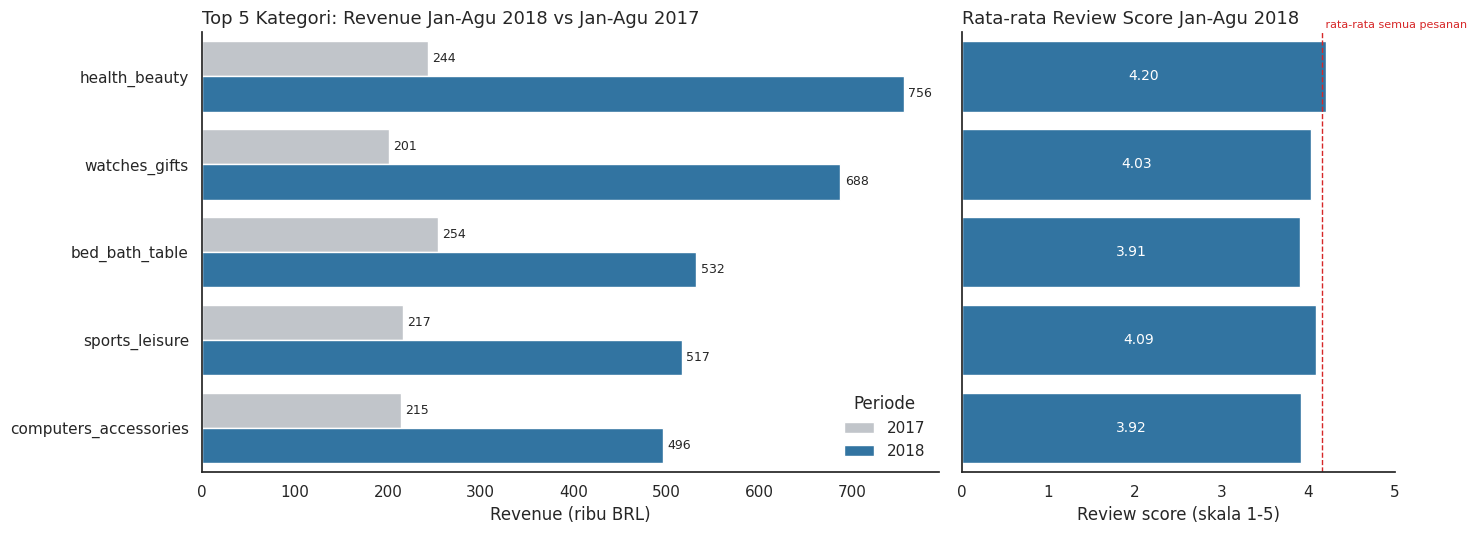

year                   revenue_2017  revenue_2018  growth_pct  avg_review
category                                                                 
health_beauty              243521.7      755724.5       210.3         4.2
watches_gifts              201137.9      687577.2       241.8         4.0
bed_bath_table             254444.8      532358.8       109.2         3.9
sports_leisure             216545.3      517166.3       138.8         4.1
computers_accessories      214631.3      496158.3       131.2         3.9


In [13]:
top5 = top_cat.head(5)
plot_df = (top5[['revenue_2017', 'revenue_2018']].reset_index()
           .melt(id_vars='category', var_name='tahun', value_name='revenue'))
plot_df['tahun'] = plot_df['tahun'].str[-4:]
plot_df['revenue_k'] = plot_df['revenue'] / 1000

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1.7, 1]})
sns.barplot(data=plot_df, y='category', x='revenue_k', hue='tahun', palette={'2017': '#BFC5CC', '2018': '#1f77b4'}, ax=ax[0])
ax[0].set_title('Top 5 Kategori: Revenue Jan-Agu 2018 vs Jan-Agu 2017', loc='left', fontsize=13)
ax[0].set_xlabel('Revenue (ribu BRL)'); ax[0].set_ylabel('')
for c in ax[0].containers: ax[0].bar_label(c, fmt='%.0f', padding=3, fontsize=9)
ax[0].legend(title='Periode', frameon=False)

sns.barplot(x=top5['avg_review'], y=top5.index, color='#1f77b4', ax=ax[1])
ax[1].axvline(order_df['review_score'].mean(), color='#d62728', ls='--', lw=1)
ax[1].text(order_df['review_score'].mean(), -0.55, ' rata-rata semua pesanan', color='#d62728', fontsize=8)
ax[1].set_xlim(0, 5); ax[1].set_title('Rata-rata Review Score Jan-Agu 2018', loc='left', fontsize=13)
ax[1].set_xlabel('Review score (skala 1-5)'); ax[1].set_ylabel(''); ax[1].set_yticklabels([])
for c in ax[1].containers: ax[1].bar_label(c, fmt='%.2f', label_type='center', color='white', fontsize=10)
sns.despine(); plt.tight_layout(); plt.show()
print(top5[['revenue_2017', 'revenue_2018', 'growth_pct', 'avg_review']].round(1))

**Insight:**
- Tiga kategori teratas Jan-Agu 2018: **health_beauty** (±755,7 ribu BRL, +210%), **watches_gifts** (±687,6 ribu, +242%), dan **bed_bath_table** (±532,4 ribu, +109%); di posisi 4-5 ada sports_leisure dan computers_accessories.
- `watches_gifts` tumbuh paling cepat di antara 5 besar, sedangkan `bed_bath_table` paling lambat tumbuhnya.
- Kepuasan pelanggan berbeda tipis: hanya `health_beauty` (4,20) yang berada di atas rata-rata semua pesanan (±4,15), sedangkan `bed_bath_table` (3,91) dan `computers_accessories` (3,92) paling rendah sehingga perlu perhatian kualitas/ekspektasi produk.

### Pertanyaan 2: State dengan pengiriman terlama / keterlambatan tertinggi dan dampaknya ke review score

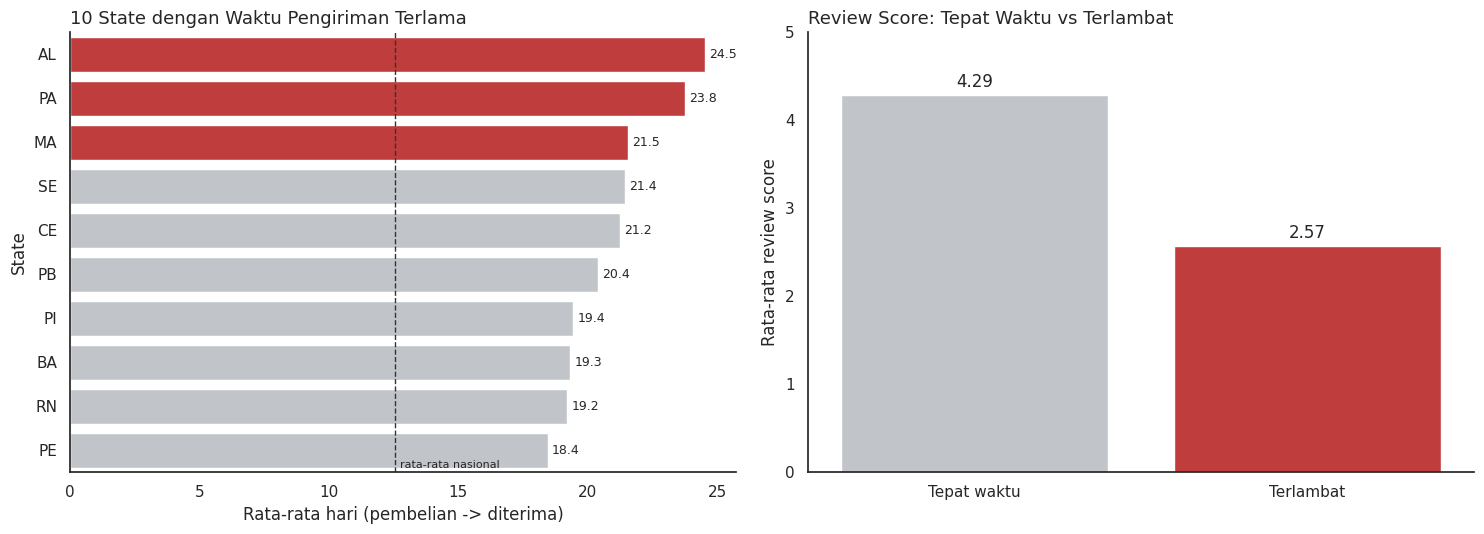

                orders  avg_delivery_days  late_pct  avg_review
customer_state                                                 
AL                 396              24.52     23.99        3.85
PA                 942              23.76     12.42        3.91
MA                 713              21.54     19.64        3.83
SE                 332              21.44     15.36        3.90
CE                1273              21.24     15.40        3.94
PB                 516              20.39     11.05        4.07
PI                 475              19.44     16.00        3.99
BA                3253              19.33     14.05        3.93
RN                 470              19.21     10.85        4.14
PE                1587              18.45     10.84        4.08


In [14]:
big = state_perf[state_perf['orders'] >= 300]    # hanya state dengan sampel memadai
slow = big.sort_values('avg_delivery_days', ascending=False).head(10)

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
colors = ['#d62728' if i < 3 else '#BFC5CC' for i in range(len(slow))]
sns.barplot(x=slow['avg_delivery_days'], y=slow.index, palette=colors, hue=slow.index, legend=False, ax=ax[0])
ax[0].axvline(order_df['delivery_days'].mean(), color='#333', ls='--', lw=1)
ax[0].text(order_df['delivery_days'].mean() + .2, 9.4, 'rata-rata nasional', fontsize=8)
ax[0].set_title('10 State dengan Waktu Pengiriman Terlama', loc='left', fontsize=13)
ax[0].set_xlabel('Rata-rata hari (pembelian -> diterima)'); ax[0].set_ylabel('State')
for c in ax[0].containers: ax[0].bar_label(c, fmt='%.1f', padding=3, fontsize=9)

sns.barplot(x=late_review.index, y=late_review['mean'], palette=['#BFC5CC', '#d62728'], hue=late_review.index, legend=False, ax=ax[1])
ax[1].set_ylim(0, 5); ax[1].set_title('Review Score: Tepat Waktu vs Terlambat', loc='left', fontsize=13)
ax[1].set_xlabel(''); ax[1].set_ylabel('Rata-rata review score')
for c in ax[1].containers: ax[1].bar_label(c, fmt='%.2f', padding=3)
sns.despine(); plt.tight_layout(); plt.show()
print(slow[['orders', 'avg_delivery_days', 'late_pct', 'avg_review']])

**Insight:**
- Di antara state dengan minimal 300 pesanan, waktu pengiriman terlama ada di **AL (24,5 hari), PA (23,8 hari), dan MA (21,5 hari)**, jauh di atas rata-rata nasional ±12 hari.
- Persentase pesanan terlambat tertinggi ada di **AL (24,0%)**, **MA (19,6%)**, dan **PI (16,0%)**, sementara rata-rata nasional hanya 8,13%.
- Keterlambatan sangat merusak kepuasan: review rata-rata **2,57** untuk pesanan terlambat vs **4,29** untuk yang tepat waktu (selisih ±1,7 poin).
- Catatan: RR, AP, dan AM punya rata-rata waktu pengiriman lebih lama lagi tetapi sampelnya <300 pesanan sehingga tidak dijadikan dasar kesimpulan.

## Analisis Lanjutan

### RFM Analysis (segmentasi pelanggan)
Recency = hari sejak pembelian terakhir (terhadap tanggal acuan 1 hari setelah transaksi terakhir), Frequency = jumlah pesanan unik, Monetary = total `price`. Segmentasi dilakukan secara **manual grouping** berdasarkan aturan bisnis.

                      pelanggan  avg_recency  avg_monetary  total_revenue  \
segment                                                                     
Berisiko                  36945        178.6         136.0      5026120.2   
Hilang (>270 hari)        35522        394.9         139.5      4956145.2   
Baru (<=90 hari)          17840         44.8         138.6      2472157.4   
Repeat (tidak aktif)       1558        321.2         252.9       394079.2   
Loyal                      1231         91.0         269.1       331275.8   

                      pct_pelanggan  
segment                              
Berisiko                       39.7  
Hilang (>270 hari)             38.2  
Baru (<=90 hari)               19.2  
Repeat (tidak aktif)            1.7  
Loyal                           1.3  


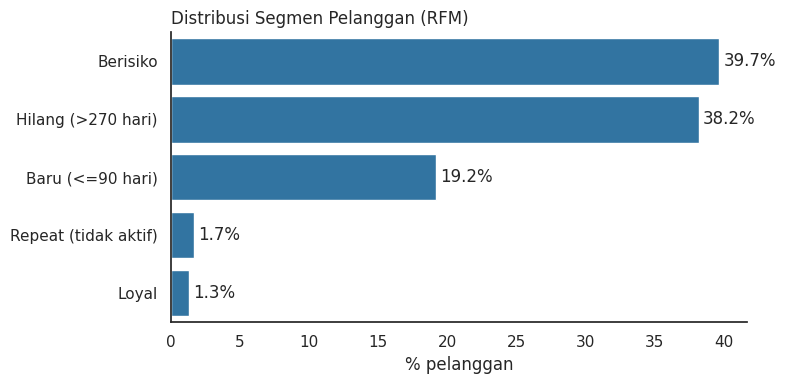

In [15]:
snapshot = main_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)
rfm = (main_df.groupby('customer_unique_id')
       .agg(last_purchase=('order_purchase_timestamp', 'max'), frequency=('order_id', 'nunique'), monetary=('price', 'sum'))
       .reset_index())
rfm['recency'] = (snapshot - rfm['last_purchase']).dt.days

def segment(r):
    if r['frequency'] >= 2 and r['recency'] <= 180: return 'Loyal'
    if r['frequency'] >= 2: return 'Repeat (tidak aktif)'
    if r['recency'] <= 90: return 'Baru (<=90 hari)'
    if r['recency'] <= 270: return 'Berisiko'
    return 'Hilang (>270 hari)'
rfm['segment'] = rfm.apply(segment, axis=1)

seg = (rfm.groupby('segment').agg(pelanggan=('customer_unique_id', 'count'), avg_recency=('recency', 'mean'),
                                  avg_monetary=('monetary', 'mean'), total_revenue=('monetary', 'sum')).round(1))
seg['pct_pelanggan'] = (seg['pelanggan'] / seg['pelanggan'].sum() * 100).round(1)
seg = seg.sort_values('pelanggan', ascending=False)
print(seg)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=seg['pct_pelanggan'], y=seg.index, color='#1f77b4', ax=ax)
for c in ax.containers: ax.bar_label(c, fmt='%.1f%%', padding=3)
ax.set_title('Distribusi Segmen Pelanggan (RFM)', loc='left'); ax.set_xlabel('% pelanggan'); ax.set_ylabel('')
sns.despine(); plt.tight_layout(); plt.show()

**Insight:**
- Hanya **1,3%** pelanggan masuk segmen *Loyal* (≥2 pesanan dan aktif ≤180 hari) dan 1,7% *Repeat tidak aktif*; mayoritas pelanggan hanya membeli satu kali.
- Segmen repeat (Loyal & Repeat) membelanjakan rata-rata ±253-269 BRL, hampir 2x pelanggan sekali beli (±136-140 BRL).
- Sebanyak 39,7% pelanggan berstatus *Berisiko* (terakhir beli 91-270 hari lalu) dengan total revenue ±5,0 juta BRL, sehingga menjadi target utama reaktivasi; 38,2% sudah *Hilang* (>270 hari).

### Geospatial Analysis (sebaran pesanan, keterlambatan, dan revenue per state)

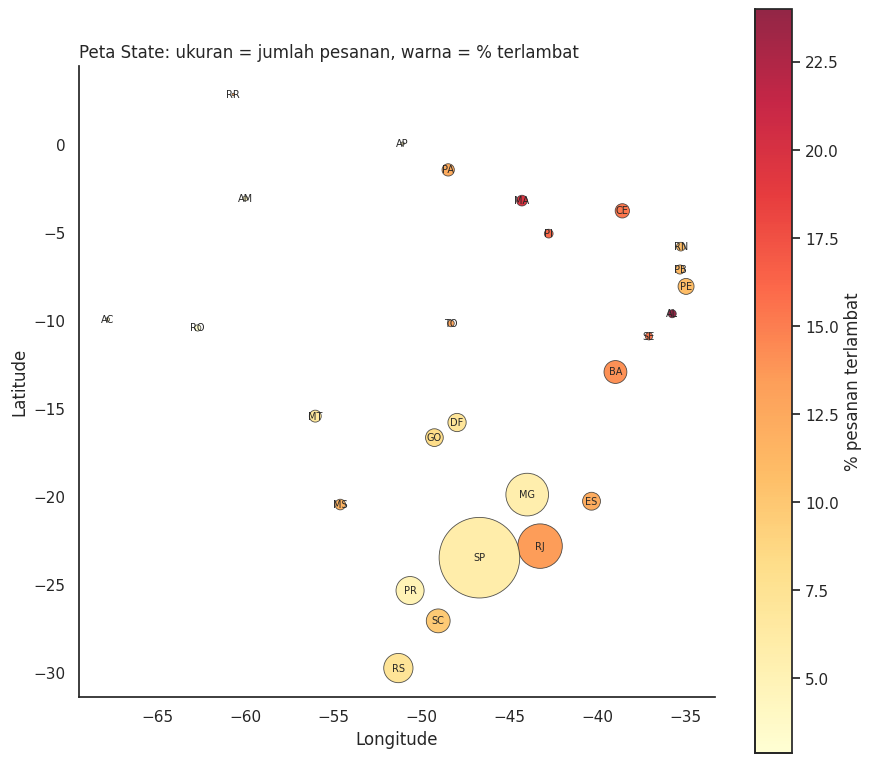

,state,orders,late_pct,revenue
1,AL,396,24.0,78805.7
9,MA,713,19.6,116305.1
16,PI,475,16.0,84511.0
5,CE,1273,15.4,218107.7
24,SE,332,15.4,56288.7


In [16]:
geo_state = pd.read_csv('dashboard/state_geo.csv')
geo_perf = (order_df.merge(main_df.groupby('order_id')['price'].sum().rename('rev'), on='order_id')
            .groupby('customer_state').agg(orders=('order_id', 'count'), late_pct=('is_late', 'mean'), revenue=('rev', 'sum'))
            .reset_index().rename(columns={'customer_state': 'state'}).merge(geo_state, on='state'))
geo_perf['late_pct'] *= 100

fig, ax = plt.subplots(figsize=(9, 8))
sc = ax.scatter(geo_perf['lng'], geo_perf['lat'], s=geo_perf['orders'] / 12, c=geo_perf['late_pct'],
                cmap='YlOrRd', edgecolor='#333', linewidth=.6, alpha=.85)
for _, r in geo_perf.iterrows():
    ax.annotate(r['state'], (r['lng'], r['lat']), ha='center', va='center', fontsize=7)
plt.colorbar(sc, label='% pesanan terlambat')
ax.set_title('Peta State: ukuran = jumlah pesanan, warna = % terlambat', loc='left')
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.set_aspect('equal')
sns.despine(); plt.tight_layout(); plt.show()
geo_perf.sort_values('late_pct', ascending=False).head(5)[['state', 'orders', 'late_pct', 'revenue']].round(1)

**Insight:**
- Pesanan sangat terkonsentrasi di Tenggara (SP, RJ, MG) yang berada dekat pusat logistik, sedangkan state Utara & Timur Laut berukuran gelembung kecil namun berwarna lebih merah (lebih sering terlambat).
- Lima state dengan persentase terlambat tertinggi: AL (24,0%), MA (19,6%), PI (16,0%), CE (15,4%), SE (15,4%) - seluruhnya di Timur Laut Brasil.

### Binning: durasi pengiriman

In [17]:
bins = [0, 7, 14, 21, 30, np.inf]
labels = ['<=7 hari', '8-14 hari', '15-21 hari', '22-30 hari', '>30 hari']
order_df = order_df.assign(delivery_bin=pd.cut(order_df['delivery_days'], bins=bins, labels=labels))
bin_df = (order_df.groupby('delivery_bin', observed=True)
          .agg(pesanan=('order_id', 'count'), avg_review=('review_score', 'mean'), late_pct=('is_late', 'mean')).round(3))
bin_df['late_pct'] *= 100
bin_df['pct_pesanan'] = (bin_df['pesanan'] / bin_df['pesanan'].sum() * 100).round(1)
bin_df

,pesanan,avg_review,late_pct,pct_pesanan
delivery_bin,,,,
<=7 hari,26038,4.418,0.9,27.1
8-14 hari,40111,4.312,1.3,41.7
15-21 hari,17653,4.139,4.8,18.3
22-30 hari,7899,3.607,31.9,8.2
>30 hari,4502,2.240,82.3,4.7


**Insight:**
- 68,8% pesanan tiba dalam ≤14 hari dengan review rata-rata 4,3-4,4 dan keterlambatan di bawah 1,5%.
- Review turun tajam seiring durasi: 3,61 untuk 22-30 hari dan **2,24** untuk >30 hari, di mana 82,3% pesanan tersebut terlambat dari estimasi.
- Ambang 21 hari terlihat menjadi titik kritis: di atas itu proporsi terlambat melonjak dari 4,8% menjadi 31,9%.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pada Jan-Agu 2018 revenue tertinggi berasal dari `health_beauty` (±755,7 ribu BRL, +210% vs 2017), `watches_gifts` (±687,6 ribu BRL, +242%), dan `bed_bath_table` (±532,4 ribu BRL, +109%). Review score kelima kategori teratas berkisar 3,91-4,20; hanya `health_beauty` (4,20) di atas rata-rata keseluruhan (±4,15), sedangkan `bed_bath_table` (3,91) dan `computers_accessories` (3,92) paling rendah.
- **Conclusion pertanyaan 2:** Pengiriman paling lama terjadi di AL (24,5 hari), PA (23,8 hari), dan MA (21,5 hari) dibanding rata-rata nasional ±12 hari; keterlambatan tertinggi di AL (24,0%), MA (19,6%), dan PI (16,0%). Pesanan terlambat mendapat review 2,57 vs 4,29 untuk yang tepat waktu, sehingga keterlambatan adalah penurun kepuasan terbesar.
- **Analisis lanjutan:** RFM menunjukkan hanya 1,3% pelanggan loyal dan 39,7% berisiko churn; geospatial menunjukkan masalah keterlambatan terkonsentrasi di Timur Laut; binning menunjukkan review jatuh tajam setelah 21 hari pengiriman.

**Rekomendasi Action Item:**
- Tingkatkan stok dan promosi pada `health_beauty` dan `watches_gifts` (pertumbuhan >200%) menjelang periode puncak, serta tinjau deskripsi/kualitas produk pada `bed_bath_table` dan `computers_accessories` yang review-nya di bawah rata-rata.
- Tambahkan mitra logistik atau gudang transit untuk wilayah Timur Laut/Utara (AL, MA, PI, CE, SE, PA) dan setel ulang estimasi pengiriman di wilayah tersebut agar sesuai kenyataan, dengan target persentase terlambat <10%.
- Prioritaskan pengiriman yang berisiko melewati 21 hari (peringatan dini + kompensasi seperti voucher) untuk menekan review rendah.
- Jalankan kampanye reaktivasi (voucher / email) untuk segmen *Berisiko* (±37 ribu pelanggan) sebelum mereka berpindah ke segmen *Hilang*, dan program loyalitas untuk mendorong pembelian ulang.